# 一条数据变多条数据

Send： 将一个任务动态分发为 N 个节点执行任务（Fan-out），每个任务可以携带不同的 State

{'poem': '《咏莲》\n玉立亭亭水云间，暗香浮动月黄昏。\n中通外直真君子，不染淤泥自超然。\n\n注：本诗以莲花为咏诵对象，通过“玉立亭亭”勾勒其形态之美，“暗香浮动”传递其清雅之韵。后两句化用周敦颐《爱莲说》意境，以“中通外直”喻其品格，尾句“不染淤泥”既写莲花自然特性，更暗含超脱世俗的人生境界，全诗虚实相生，物我交融。', 'ci_poem': '《鹧鸪天·咏莲》\n玉骨沉波出素浔，田田翠盖自浮沉。\n中通外直君子器，不蔓不枝清净心。\n风举袂，露沾襟，蜻蜓立处有知音。\n濂溪一赋千秋后，谁解淤泥用意深？\n\n注：我的创作思路是围绕莲花“出淤泥而不染”的核心意象展开。上阕通过“玉骨”“翠盖”等意象展现莲的形态美，化用周敦颐“中通外直”的经典评价。下阕以动态描写引入蜻蜓意象，暗合“小荷才露尖尖角”的古典意境，结句点出淤泥与高洁的辩证关系，赋予传统意象以新的哲思深度。', 'joke': '## 莲花笑话\n\n1. **莲藕的凡尔赛**\n  荷花问莲藕：“你天天在泥里，不觉得委屈吗？”\n  莲藕说：“委屈啥？我七个心眼儿，比你们谁都多。”\n\n2. **莲花的职业规划**\n  小莲花问老莲花：“咱们长大了做什么？”\n  老莲花说：“要么当花供人观赏，要么当药材治病救人，要么……”\n  小莲花：“要么什么？”\n  老莲花：“要么跟藕一样，去火锅店上班。”\n\n3. **出淤泥而不染**\n  朋友夸我：“你真像莲花，出淤泥而不染。”\n  我感动地说：“谢谢，你是说我品格高尚？”\n  朋友：“不，我是说你泡在泥里还能装得跟没事儿人一样。”\n\n4. **莲子的烦恼**\n  莲子对莲蓬说：“妈，我什么时候能出去看看世界？”\n  莲蓬说：“等你变硬了再说。”\n  莲子：“那我变硬了能去哪？”\n  莲蓬：“银耳汤里。”\n\n5. **荷叶的自我认知**\n  荷叶对青蛙说：“大家都夸我像伞，你觉得呢？”\n  青蛙说：“像，特别像。”\n  荷叶很开心：“那我是不是很优雅？”\n  青蛙：“像伞没错，但你是那种下雨天被人忘在公交车上、最后长蘑菇的伞。”\n\n6. **莲花的凡尔赛文学**\n  蔷薇：“我开花可香了。”\n  玫瑰：“我开花能送人。”\n  莲花：“我开花吧……佛教、道教、文人画、陶瓷艺术、国宴摆盘都得找我。我也

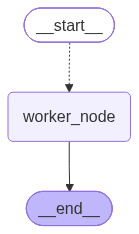

In [1]:
from typing import TypedDict,Literal,Sequence
from wsgiref.util import request_uri

from IPython.core.debugger import prompt
from PIL import WalImageFile
from langchain_deepseek import ChatDeepSeek
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langchain.messages import HumanMessage
from dotenv import load_dotenv

load_dotenv(override=True)

CONTENT_TYPES = ["poem","joke","ci_poem"]

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

#1. 定义状态
#1.1 全局状态
class OverAllState(TypedDict):
    topic: str
    poem: str
    ci_poem:str
    joke: str

#1.2 私有状态
class WorkerState(TypedDict):
    content_type: Literal["poem","joke","ci_poem"]
    prompt: str

#1.3 输入状态
class InputState(TypedDict):
    topic: str

#1.4 输出状态
class OutputState(TypedDict):
    poem: str
    ci_poem:str
    joke: str

# 2. 定义节点
def worker_node(state:WorkerState) -> OutputState:
    content_type = state["content_type"]
    prompt = state["prompt"]
    content = model.invoke([HumanMessage(prompt)]).content
    return {
        content_type: content
    }

#3. 定义动态分支的路由
def router(state:InputState) -> Sequence[Send]:
    router_prompt = "请生成关于{} 的 {}"
    english2Chinese = {
        "poem": "七言绝句",
        "joke": "笑话",
        "ci_poem": "中文词"
    }
    topic = state["topic"]
    return [
        Send(
            "worker_node",
            {
                "content_type": content_type,
                "prompt": router_prompt.format(topic, english2Chinese[content_type])
            }
        )
        for content_type in CONTENT_TYPES
    ]

#4. 构建图
builder = StateGraph(state_schema=OverAllState, input_schema=InputState, output_schema=OutputState)

builder.add_node("worker_node", worker_node)
builder.add_conditional_edges(
    START,
    router,
    path_map=["worker_node"],
    )

builder.add_edge("worker_node",END)

graph = builder.compile()
res = graph.invoke({"topic": "莲花"})
print(res)

from IPython.display import display
display(graph)


